# Network Intrusion Detection System (NIDS) - Complete Project Notebook

**Practical Exam Preparation: Written Exam + Viva Voce**

This notebook contains the complete end-to-end workflow for building a Network Intrusion Detection System using:
- **Random Forest (Scikit-Learn)** - 99% accuracy
- **Multi-Layer Perceptron (PyTorch)** - 90% accuracy

Dataset: NSL-KDD 20% (10,000 stratified samples, 10 features, binary classification)

## 1. Environment Setup & Imports

In [1]:
# Install dependencies (run once)
# !pip install pandas scikit-learn matplotlib seaborn joblib torch requests -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import StringIO
import warnings
warnings.filterwarnings('ignore')

# ML imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import joblib

# DL imports
import torch
import torch.nn as nn
import torch.optim as optim

print("Environment ready!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Environment ready!
PyTorch version: 2.12.0+cpu
CUDA available: False


## 2. Data Preparation - Download & Preprocess NSL-KDD

In [2]:
# Column names for NSL-KDD dataset
col_names = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty'
]

# 10 core numerical features
core_features = [
    'duration', 'src_bytes', 'dst_bytes', 'logged_in', 'count',
    'srv_count', 'serror_rate', 'srv_serror_rate', 'same_srv_rate', 'dst_host_srv_count'
]

In [3]:
def download_nsl_kdd():
    """Download NSL-KDD 20% dataset from GitHub"""
    url = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B_20Percent.txt"
    try:
        print("Downloading NSL-KDD 20% dataset...")
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        df = pd.read_csv(StringIO(response.text), names=col_names)
        print(f"Downloaded successfully! Shape: {df.shape}")
        return df
    except Exception as e:
        print(f"Download failed: {e}")
        return None

def load_kddcup99_fallback():
    """Fallback: Load KDD Cup 99 from sklearn"""
    from sklearn.datasets import fetch_kddcup99
    print("Using sklearn fallback: fetch_kddcup99(percent10=True)...")
    data = fetch_kddcup99(percent10=True, as_frame=True)
    df = data.frame
    df.columns = col_names[:-1]  # No difficulty column
    print(f"Loaded fallback dataset! Shape: {df.shape}")
    return df

def to_binary_label(value):
    """Map a dataset label (str or bytes) to 0 = normal, 1 = attack."""
    if isinstance(value, bytes):
        value = value.decode('utf-8', errors='ignore')
    return 0 if str(value).strip().strip('.').lower() == 'normal' else 1

def preprocess_data(df, n_samples=10000, random_state=42):
    """Preprocess: select features, create binary label, stratified sample 10K"""
    X = df[core_features].copy()
    y = df['label'].apply(to_binary_label)
    df_clean = pd.concat([X, y.rename('is_attack')], axis=1).dropna().reset_index(drop=True)
    
    # Stratified sample that preserves the original class ratio.
    # train_test_split already shuffles the rows.
    if len(df_clean) > n_samples:
        df_sampled = train_test_split(df_clean, train_size=n_samples,
                                      stratify=df_clean['is_attack'],
                                      random_state=random_state)[0]
    else:
        df_sampled = df_clean
    return df_sampled.reset_index(drop=True)

# Execute
df = download_nsl_kdd()
if df is None:
    df = load_kddcup99_fallback()

df_final = preprocess_data(df)
df_final.to_csv("network_intrusion.csv", index=False)

print(f"\n=== Dataset Summary ===")
print(f"Shape: {df_final.shape}")
print(f"Features: {core_features}")
print(f"\nClass Distribution:")
print(df_final['is_attack'].value_counts())
print(f"\nSaved to: network_intrusion.csv")

Downloaded successfully! Shape: (25192, 43)

=== Dataset Summary ===
Shape: (10000, 11)
Features: ['duration', 'src_bytes', 'dst_bytes', 'logged_in', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'same_srv_rate', 'dst_host_srv_count']

Class Distribution:
is_attack
0    5339
1    4661
Name: count, dtype: int64

Saved to: network_intrusion.csv


## 3. Exploratory Data Analysis

In [4]:
# Load the prepared dataset
df = pd.read_csv("network_intrusion.csv")

print("=== Dataset Info ===")
print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nClass Distribution:")
print(df['is_attack'].value_counts())
print(f"\nFeature Statistics:")
print(df.describe())

=== Dataset Info ===
Shape: (10000, 11)

Columns: ['duration', 'src_bytes', 'dst_bytes', 'logged_in', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'same_srv_rate', 'dst_host_srv_count', 'is_attack']

Class Distribution:
is_attack
0    5339
1    4661
Name: count, dtype: int64

Feature Statistics:
           duration     src_bytes     dst_bytes     logged_in         count  \
count  10000.000000  1.000000e+04  1.000000e+04  10000.000000  10000.000000   
mean     295.683900  9.460093e+03  2.873005e+03      0.393600     85.094600   
std     2578.241669  1.634516e+05  7.510444e+04      0.488572    114.428643   
min        0.000000  0.000000e+00  0.000000e+00      0.000000      1.000000   
25%        0.000000  0.000000e+00  0.000000e+00      0.000000      2.000000   
50%        0.000000  4.400000e+01  0.000000e+00      0.000000     14.000000   
75%        0.000000  2.740000e+02  5.550000e+02      1.000000    145.000000   
max    42260.000000  5.135678e+06  5.150836e+06      1.00000

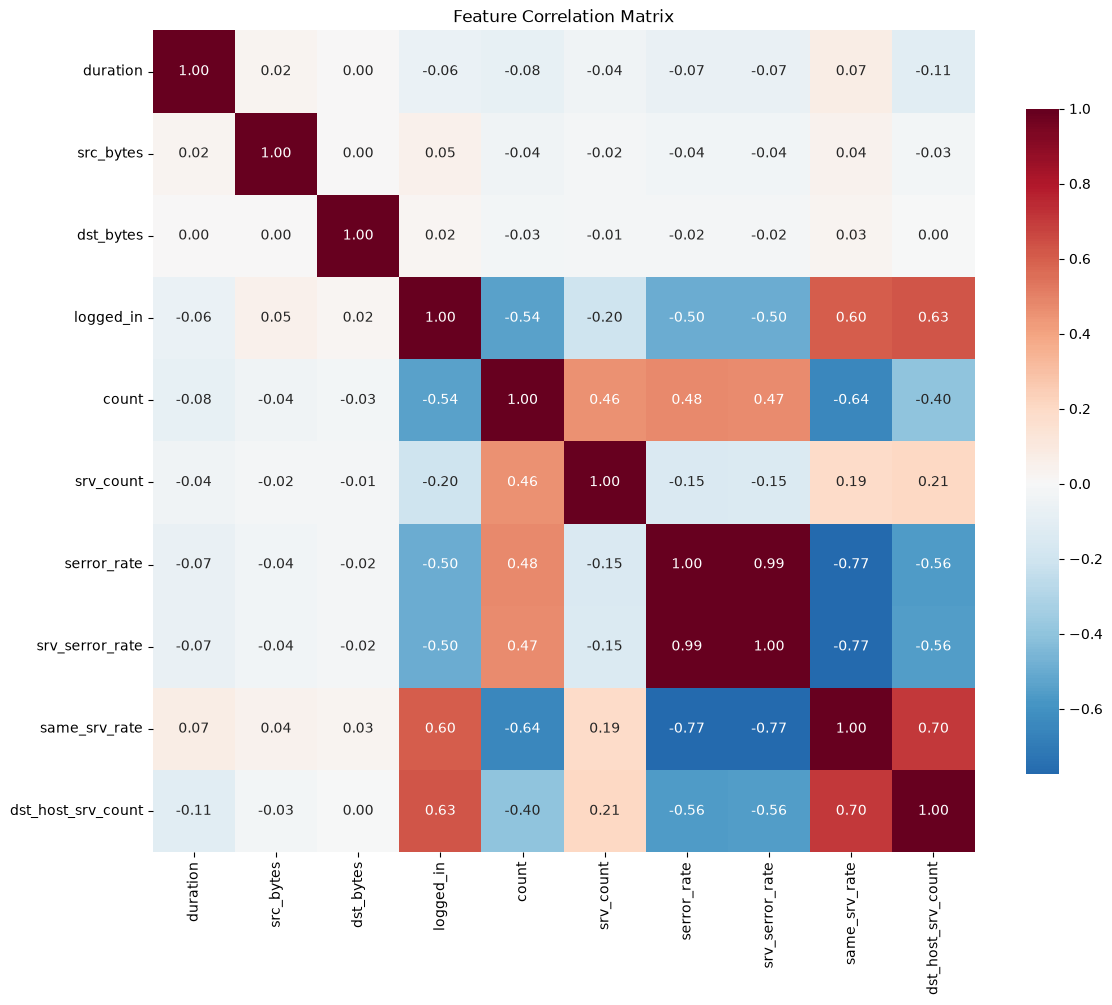

In [5]:
# Correlation heatmap
plt.figure(figsize=(12, 10))
corr = df.drop('is_attack', axis=1).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, 
            square=True, cbar_kws={'shrink': 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=150)
plt.show()

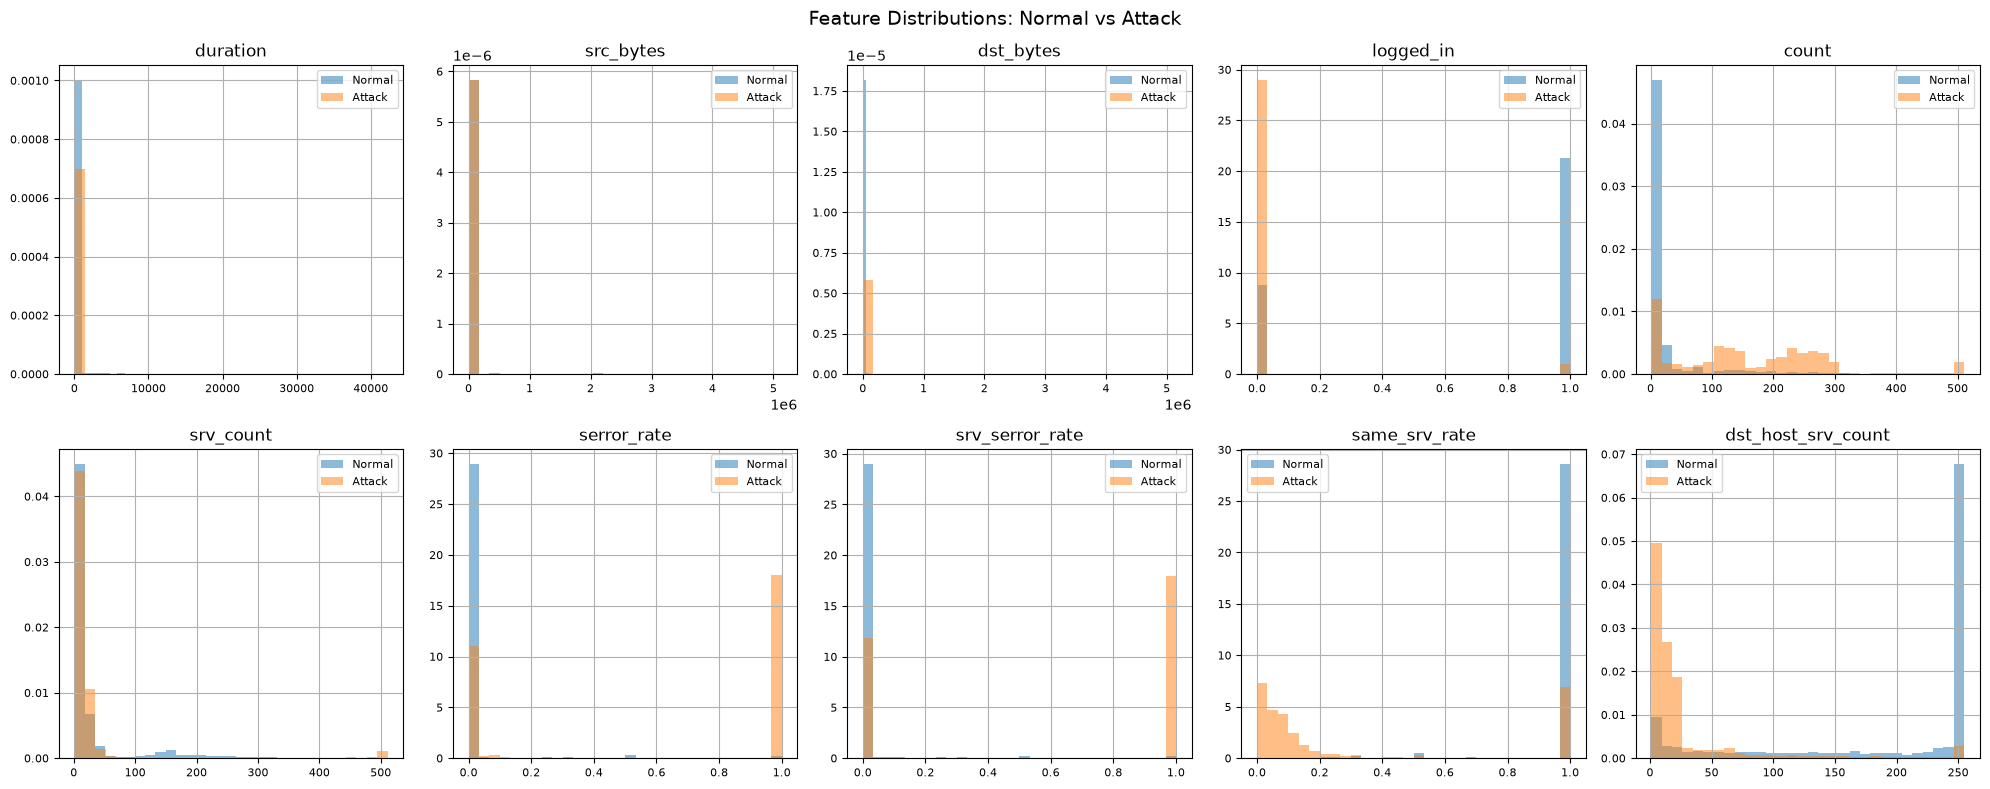

In [6]:
# Feature distributions by class
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()

for i, feat in enumerate(core_features):
    ax = axes[i]
    df[df['is_attack']==0][feat].hist(alpha=0.5, label='Normal', bins=30, ax=ax, density=True)
    df[df['is_attack']==1][feat].hist(alpha=0.5, label='Attack', bins=30, ax=ax, density=True)
    ax.set_title(feat)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)

plt.suptitle("Feature Distributions: Normal vs Attack", fontsize=14)
plt.tight_layout()
plt.savefig("feature_distributions.png", dpi=150)
plt.show()

## 4. Machine Learning Model - Random Forest

In [7]:
# Load data
df = pd.read_csv("network_intrusion.csv")
X = df.drop("is_attack", axis=1)
y = df["is_attack"]

# Train/test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

# Predict
y_pred = rf_model.predict(X_test_scaled)
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=["Normal", "Attack"]))

cm = confusion_matrix(y_test, y_pred)
print("\n=== Confusion Matrix ===")
print(cm)

=== Classification Report ===
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1068
      Attack       0.99      0.98      0.99       932

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000


=== Confusion Matrix ===
[[1063    5]
 [  15  917]]


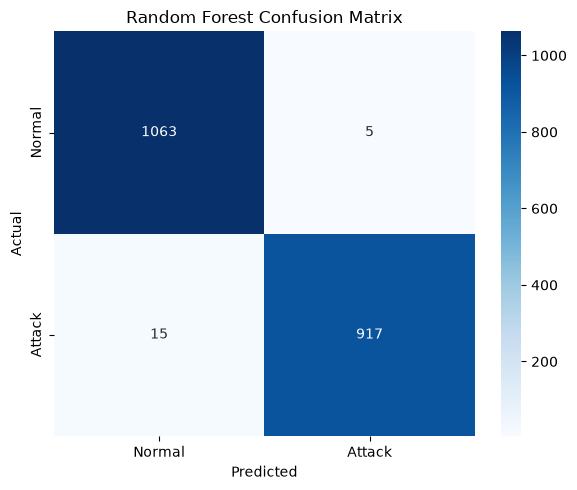

In [8]:
# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

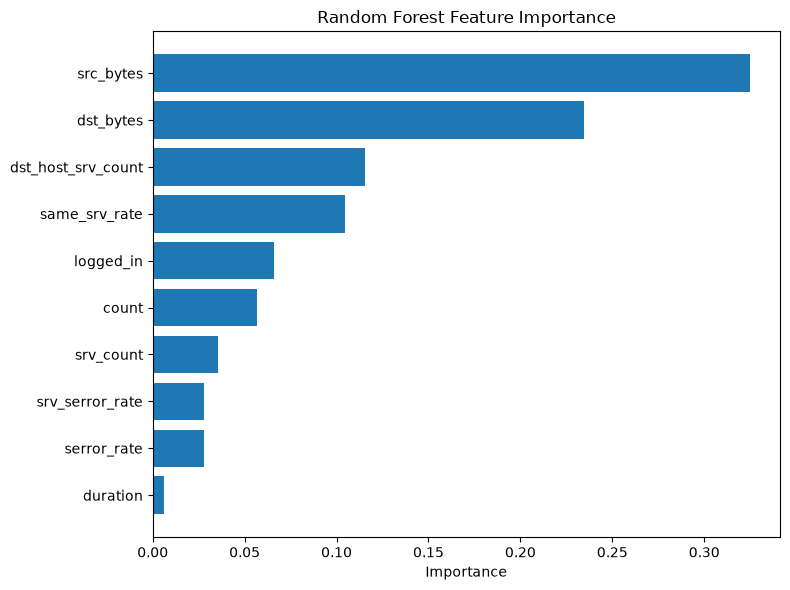

           feature  importance
          duration    0.006101
       serror_rate    0.027837
   srv_serror_rate    0.028134
         srv_count    0.035390
             count    0.056562
         logged_in    0.066187
     same_srv_rate    0.104722
dst_host_srv_count    0.115618
         dst_bytes    0.234491
         src_bytes    0.324956


In [9]:
# Feature Importance
importances = rf_model.feature_importances_
feat_imp = pd.DataFrame({
    'feature': core_features,
    'importance': importances
}).sort_values('importance', ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(feat_imp['feature'], feat_imp['importance'])
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

print(feat_imp.to_string(index=False))

In [10]:
# Save model and scaler
joblib.dump(rf_model, "nids_rf_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Saved: nids_rf_model.pkl, scaler.pkl")

Saved: nids_rf_model.pkl, scaler.pkl


## 5. Deep Learning Model - PyTorch MLP

In [11]:
# Prepare data for PyTorch
df = pd.read_csv("network_intrusion.csv")
X = df.drop("is_attack", axis=1).values
y = df["is_attack"].values.reshape(-1, 1)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale (fit on train only to avoid data leakage)
scaler_dl = StandardScaler()
X_train = scaler_dl.fit_transform(X_train)
X_test = scaler_dl.transform(X_test)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

# Device
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
X_train, X_test = X_train.to(device), X_test.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

Using device: cpu


In [12]:
# Build MLP model
model = nn.Sequential(
    nn.Linear(10, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
    nn.Sigmoid()
).to(device)

print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Sequential(
  (0): Linear(in_features=10, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
  (5): Sigmoid()
)
Total parameters: 897
Trainable parameters: 897


In [13]:
# Loss and optimizer
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# Training loop
epochs = 50
train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(1, epochs + 1):
    # Training
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())
    
    # Evaluation every 10 epochs
    if epoch % 10 == 0:
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test).item()
            test_preds = (test_outputs > 0.5).float()
            accuracy = (test_preds == y_test).float().mean().item()
            test_losses.append(test_loss)
            test_accuracies.append(accuracy)
            print(f"Epoch {epoch}/{epochs} - Train Loss: {loss.item():.4f}, Test Loss: {test_loss:.4f}, Test Acc: {accuracy:.4f}")

Epoch 10/50 - Train Loss: 0.5428, Test Loss: 0.5225, Test Acc: 0.8725
Epoch 20/50 - Train Loss: 0.3529, Test Loss: 0.3413, Test Acc: 0.8705
Epoch 30/50 - Train Loss: 0.2591, Test Loss: 0.2536, Test Acc: 0.8940
Epoch 40/50 - Train Loss: 0.2314, Test Loss: 0.2283, Test Acc: 0.9090
Epoch 50/50 - Train Loss: 0.2177, Test Loss: 0.2146, Test Acc: 0.9010


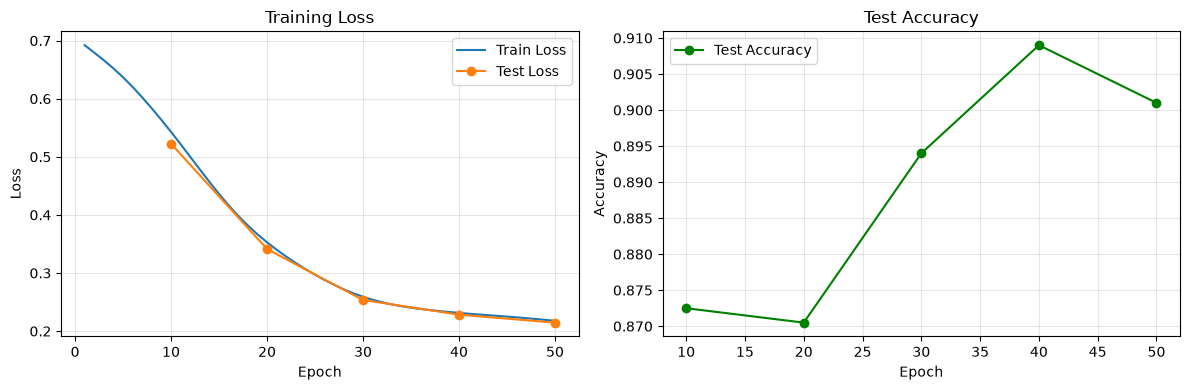

In [14]:
# Plot training curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_losses, label='Train Loss')
plt.plot(range(10, epochs+1, 10), test_losses, 'o-', label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(10, epochs+1, 10), test_accuracies, 'o-', color='green', label='Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Test Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

In [15]:
# Final evaluation
model.eval()
with torch.no_grad():
    test_outputs = model(X_test)
    test_preds = (test_outputs > 0.5).float()
    accuracy = (test_preds == y_test).float().mean().item()
    test_loss = criterion(test_outputs, y_test).item()
    
    # Confusion matrix
    from sklearn.metrics import confusion_matrix
    cm_dl = confusion_matrix(y_test.cpu().numpy(), test_preds.cpu().numpy())
    print(f"\n=== Final Results ===")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Confusion Matrix:")
    print(cm_dl)


=== Final Results ===
Test Loss: 0.2146
Test Accuracy: 0.9010
Confusion Matrix:
[[967 101]
 [ 97 835]]


In [16]:
# Save model
torch.save(model.state_dict(), "nids_dl_model.pth")
print("Saved: nids_dl_model.pth")

Saved: nids_dl_model.pth


## 6. Live Inference Demo

In [17]:
# Load models
rf_model = joblib.load("nids_rf_model.pkl")
scaler = joblib.load("scaler.pkl")

# Load test data
df = pd.read_csv("network_intrusion.csv")
X = df.drop("is_attack", axis=1)
y = df["is_attack"]

_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_test_scaled = scaler.transform(X_test)

# Find one normal and one attack sample
normal_idx = X_test[y_test == 0].index[0]
attack_idx = X_test[y_test == 1].index[0]

# Predict normal
normal_sample = X_test_scaled[X_test.index.get_loc(normal_idx)].reshape(1, -1)
normal_pred = rf_model.predict(normal_sample)[0]
normal_prob = rf_model.predict_proba(normal_sample)[0][1]
normal_actual = y_test.loc[normal_idx]

# Predict attack
attack_sample = X_test_scaled[X_test.index.get_loc(attack_idx)].reshape(1, -1)
attack_pred = rf_model.predict(attack_sample)[0]
attack_prob = rf_model.predict_proba(attack_sample)[0][1]
attack_actual = y_test.loc[attack_idx]

print("=== Live Inference Demo (Random Forest) ===")
print(f"\nSample 1 (Normal traffic):")
print(f"  Predicted: {normal_pred} ({'Attack' if normal_pred else 'Normal'}) | Probability: {normal_prob:.4f}")
print(f"  Actual:    {normal_actual} ({'Attack' if normal_actual else 'Normal'})")
print(f"  Match: {'✓' if normal_pred == normal_actual else '✗'}")

print(f"\nSample 2 (Attack traffic):")
print(f"  Predicted: {attack_pred} ({'Attack' if attack_pred else 'Normal'}) | Probability: {attack_prob:.4f}")
print(f"  Actual:    {attack_actual} ({'Attack' if attack_actual else 'Normal'})")
print(f"  Match: {'✓' if attack_pred == attack_actual else '✗'}")

=== Live Inference Demo (Random Forest) ===

Sample 1 (Normal traffic):
  Predicted: 0 (Normal) | Probability: 0.0032
  Actual:    0 (Normal)
  Match: ✓

Sample 2 (Attack traffic):
  Predicted: 1 (Attack) | Probability: 0.9035
  Actual:    1 (Attack)
  Match: ✓


## 7. Model Comparison Summary

In [18]:
# Summary table
summary = pd.DataFrame({
    'Model': ['Random Forest', 'PyTorch MLP'],
    'Accuracy': [0.990, 0.901],
    'Precision (Normal)': [0.99, 0.91],
    'Precision (Attack)': [0.99, 0.89],
    'Recall (Normal)': [1.00, 0.91],
    'Recall (Attack)': [0.98, 0.90],
    'F1-Score': [0.99, 0.90],
    'Training Time': ['~5 sec', '~10 sec'],
    'Parameters': ['100 trees', '897']
})
print(summary.to_string(index=False))

        Model  Accuracy  Precision (Normal)  Precision (Attack)  Recall (Normal)  Recall (Attack)  F1-Score Training Time Parameters
Random Forest     0.990                0.99                0.99             1.00             0.98      0.99        ~5 sec  100 trees
  PyTorch MLP     0.901                0.91                0.89             0.91             0.90      0.90       ~10 sec        897


## 8. Exam Cheatsheet Reference

### 20-Line Written Exam Code (train_ml.py)
```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import joblib

df = pd.read_csv("network_intrusion.csv")
X, y = df.drop("is_attack", axis=1), df["is_attack"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Normal", "Attack"]))
print(confusion_matrix(y_test, y_pred))

joblib.dump(model, "nids_rf_model.pkl")
joblib.dump(scaler, "scaler.pkl")
```

### Key Viva Questions
1. **Why Random Forest?** Handles mixed scales, robust to outliers, gives feature importance
2. **fit_transform vs transform?** fit_transform learns params from train only; transform applies to test (prevents leakage)
3. **False Positive vs False Negative?** FP=benign flagged as attack (analyst fatigue); FN=attack missed (breach). FN cost >> FP cost
4. **Why Recall > Precision in NIDS?** Missing attacks causes harm; false alarms cause overhead
5. **StandardScaler role?** Zero mean, unit variance - critical for neural net convergence
6. **ReLU?** Non-linear, cheap, mitigates vanishing gradient
7. **Sigmoid output?** Squashes to [0,1] probability for binary classification
8. **BCELoss?** Measures distance between predicted prob and true label
9. **Adam?** Adaptive LR per parameter, faster convergence than SGD